# 06 — Architecture trace: tensors, layers, gradients, and what a 3D convolution would cost

Phase I asks for "a working architecture with layer-level explanation and tensor flow". This notebook
produces that from the model the other notebooks train, on one real camera-trap batch: the shape at every
block, the parameter and activation memory it costs, what the first convolution layer actually looks like,
where the classifier is looking (Grad-CAM, which only works if gradients really flow), and the 2D-vs-3D
convolution comparison the syllabus asks for — measured, not asserted.

In [1]:
import json, os, sys, time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from PIL import Image
from torchvision import transforms as T
from torchvision.models import resnet50

ROOT = next(a for a in [Path.cwd(), *Path.cwd().parents] if (a / "data/splits").exists())
sys.path.insert(0, str(ROOT / "src/vision"))
import wildlife as W

IMG_ROOT = ROOT / "data/raw/iwildcam_v2.0/train"
SPLITS_DIR = ROOT / "data/splits"
WEIGHTS = Path(os.path.expanduser("~/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth"))
OUT = Path(os.environ.get("P11_OUT", ROOT / "outputs/logs/notebook06"))
OUT.mkdir(parents=True, exist_ok=True)
W.set_seed()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class_map = pd.read_csv(SPLITS_DIR / "class_map.csv").set_index("label")["class_name"]
N_CLASSES = len(class_map)
train_tbl = W.on_disk(pd.read_csv(SPLITS_DIR / "train.csv"), IMG_ROOT, verbose=False)
# One image per class so every shape row below is a real forward pass, not synthetic noise.
sample = train_tbl.groupby("label").head(1).reset_index(drop=True)
print(json.dumps({"images_sampled": len(sample), "classes": N_CLASSES,
                  "weights": WEIGHTS.name, **W.hardware_note()}, indent=2))

{
  "images_sampled": 13,
  "classes": 13,
  "weights": "resnet50-11ad3fa6.pth",
  "device": "cuda",
  "torch": "2.7.1+cu118",
  "gpu": "NVIDIA GeForce RTX 3060 Laptop GPU",
  "vram_gb": 6.0
}


In [2]:
eval_tf = T.Compose([T.Resize((224, 224)), T.ToTensor(),
                     T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])
raw = [Image.open(IMG_ROOT / f).convert("RGB") for f in sample.filename]
x = torch.stack([eval_tf(im) for im in raw]).to(DEVICE)
y = torch.tensor(sample.label.tolist())
print("batch tensor:", tuple(x.shape), "| pixel range after normalisation:",
      round(float(x.min()), 2), "to", round(float(x.max()), 2))

model = W.load_resnet50(WEIGHTS, n_classes=N_CLASSES, pretrained=True).to(DEVICE).eval()
print("head replaced with:", model.fc)

batch tensor: (13, 3, 224, 224) | pixel range after normalisation: -2.12 to 2.64


loaded resnet50-11ad3fa6.pth (318 tensors), head replaced
head replaced with: Linear(in_features=2048, out_features=13, bias=True)


## 1. Tensor flow, measured by hooks

Every block reports its output shape, parameter count and activation memory for this real batch. These are
the numbers to recite in the viva: 224 px enters, the stem quarters it, each stage halves the spatial size
and doubles the channels, global average pooling turns `7x7x2048` into `2048`, and the head maps that to
13 species.

In [3]:
blocks = {"stem (conv7x7, bn, relu, maxpool)": model.conv1, "layer1": model.layer1,
          "layer2": model.layer2, "layer3": model.layer3, "layer4": model.layer4,
          "avgpool": model.avgpool, "flatten": model.flatten if hasattr(model, "flatten") else None,
          "fc": model.fc}
records, hooks = [], []


def hook(name):
    def fn(module, inputs, output):
        shape = tuple(output.shape)
        params = sum(p.numel() for p in module.parameters(recurse=True))
        mem_mb = output.numel() * output.element_size() / 2**20
        records.append({"block": name, "out_shape": str(shape), "params_M": round(params / 1e6, 3),
                        "activation_MB": round(mem_mb, 2), "channels": shape[1] if len(shape) > 1 else None})
        for i in inputs:
            if torch.is_tensor(i):
                records[-1]["in_shape"] = str(tuple(i.shape))
                break
    return fn


for name, mod in blocks.items():
    if mod is None:
        continue
    hooks.append(mod.register_forward_hook(hook(name)))
with torch.no_grad():
    logits = model(x)
for h in hooks:
    h.remove()
flow = pd.DataFrame(records).drop_duplicates(subset=["block"])
print(flow.to_string(index=False))
print("\nlogits:", tuple(logits.shape), "| predicted classes:",
      [class_map[i] for i in logits.argmax(1).tolist()][:6], "...")
total_params = sum(p.numel() for p in model.parameters())
trainable_all = total_params  # all trainable would be the unfrozen case
print(f"total parameters: {total_params/1e6:.2f} M ; head parameters: "
      f"{sum(p.numel() for p in model.fc.parameters())/1e3:.1f} k")
flow.to_csv(OUT / "tensor_flow.csv", index=False)

                            block          out_shape  params_M  activation_MB  channels           in_shape
stem (conv7x7, bn, relu, maxpool) (13, 64, 112, 112)     0.009          39.81        64  (13, 3, 224, 224)
                           layer1  (13, 256, 56, 56)     0.216          39.81       256   (13, 64, 56, 56)
                           layer2  (13, 512, 28, 28)     1.220          19.91       512  (13, 256, 56, 56)
                           layer3 (13, 1024, 14, 14)     7.098           9.95      1024  (13, 512, 28, 28)
                           layer4   (13, 2048, 7, 7)    14.965           4.98      2048 (13, 1024, 14, 14)
                          avgpool   (13, 2048, 1, 1)     0.000           0.10      2048   (13, 2048, 7, 7)
                               fc           (13, 13)     0.027           0.00        13         (13, 2048)

logits: (13, 13) | predicted classes: ['cephalophus nigrifrons', 'tayassu pecari', 'tayassu pecari', 'bos taurus', 'crax rubra', 'meleagris oce

## 1b. Layer diagram, drawn from the measured shapes

The rubric asks for a layer diagram alongside tensor shapes, so this one is generated from the hook records
above rather than typed from memory — figure and table then cannot disagree. The second row places the
classifier inside the product: what a frame becomes on the way to a ranger's queue, and where the detector and
the alert rule sit.

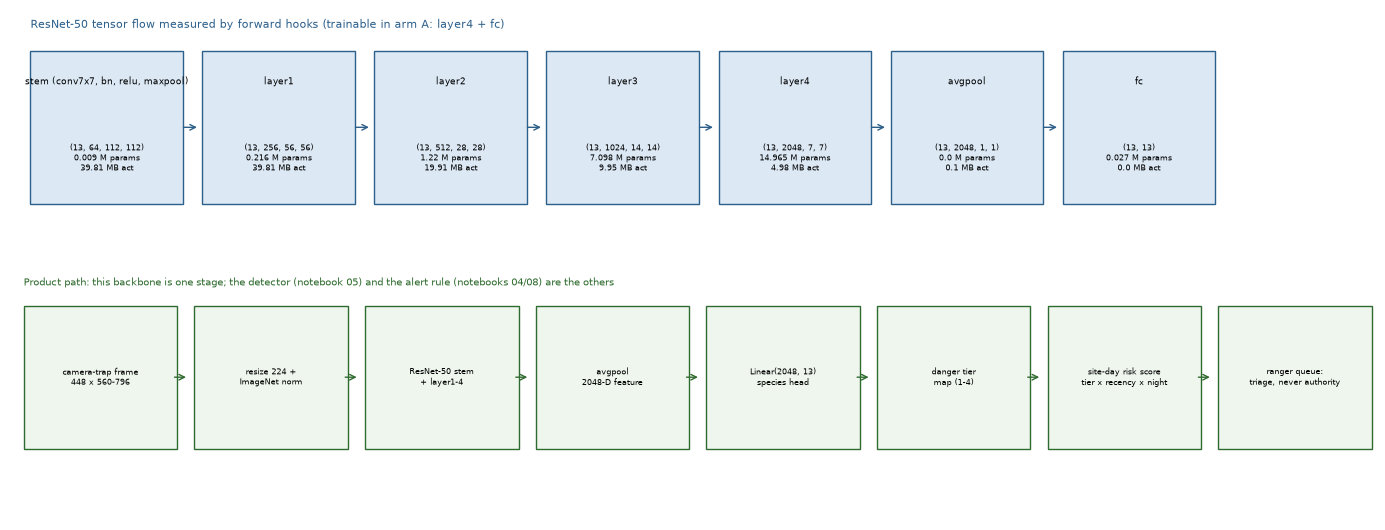

saved C:\Users\xxshi\Desktop\PYTHOM\DL_PBL\outputs\logs\notebook06\architecture_diagram.png | backbone blocks drawn: 7


In [4]:
dg_rows = pd.DataFrame(records)
dg_fig, dg_ax = plt.subplots(figsize=(14, 5.4))
dg_ax.axis("off")
dg_bw, dg_gap = 0.112, 0.014
for dg_k, dg_r in enumerate(dg_rows.to_dict("records")):
    dg_x = 0.015 + dg_k * (dg_bw + dg_gap)
    dg_ax.add_patch(plt.Rectangle((dg_x, 0.62), dg_bw, 0.30, facecolor="#dce9f5", edgecolor="#2c5f8a"))
    dg_ax.text(dg_x + dg_bw / 2, 0.86, dg_r["block"], ha="center", va="center", fontsize=6.5)
    dg_ax.text(dg_x + dg_bw / 2, 0.71, f"{dg_r['out_shape']}\n{dg_r['params_M']} M params\n"
               f"{dg_r['activation_MB']} MB act", ha="center", va="center", fontsize=6)
    if dg_k:
        dg_ax.annotate("", xy=(dg_x - 0.002, 0.77), xytext=(dg_x - dg_gap - 0.002, 0.77),
                       arrowprops=dict(arrowstyle="->", color="#2c5f8a"))
dg_ax.text(0.015, 0.965, "ResNet-50 tensor flow measured by forward hooks (trainable in arm A: layer4 + fc)",
           fontsize=8, color="#2c5f8a")
dg_chain = ["camera-trap frame\n448 x 560-796", "resize 224 +\nImageNet norm",
            "ResNet-50 stem\n+ layer1-4", "avgpool\n2048-D feature",
            "Linear(2048, 13)\nspecies head", "danger tier\nmap (1-4)",
            "site-day risk score\ntier x recency x night", "ranger queue:\ntriage, never authority"]
dg_cw = 1.0 / len(dg_chain)
for dg_j, dg_label in enumerate(dg_chain):
    dg_cx = 0.01 + dg_j * dg_cw
    dg_ax.add_patch(plt.Rectangle((dg_cx, 0.14), dg_cw * 0.9, 0.28, facecolor="#eef6ee", edgecolor="#2f6b2f"))
    dg_ax.text(dg_cx + dg_cw * 0.45, 0.28, dg_label, ha="center", va="center", fontsize=6)
    if dg_j:
        dg_ax.annotate("", xy=(dg_cx - 0.004, 0.28), xytext=(dg_cx - dg_cw * 0.1 - 0.004, 0.28),
                       arrowprops=dict(arrowstyle="->", color="#2f6b2f"))
dg_ax.text(0.01, 0.46, "Product path: this backbone is one stage; the detector (notebook 05) and the alert "
                       "rule (notebooks 04/08) are the others", fontsize=7.5, color="#2f6b2f")
dg_fig.tight_layout()
dg_fig.savefig(OUT / "architecture_diagram.png", dpi=130)
plt.show()
print("saved", OUT / "architecture_diagram.png", "| backbone blocks drawn:", len(dg_rows))

## 2. The learned filters and where the model looks

Two things examiners ask: what does the first convolution actually contain, and can you show the gradient
path from the class score back to the image. Grad-CAM answers both at once — it fails if gradients do not
reach `layer4`.

conv1 weight shape: (64, 3, 7, 7) | each filter sees 147 input values, total 9408 weights


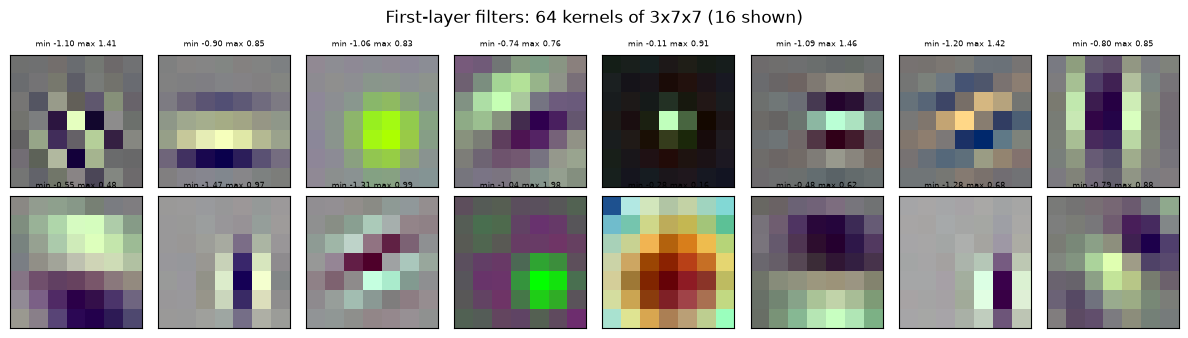

In [5]:
w0 = model.conv1.weight.detach().cpu()           # [64, 3, 7, 7]
grid = w0[:16].permute(0, 2, 3, 1).numpy()
fig, axes = plt.subplots(2, 8, figsize=(12, 3.4), subplot_kw={"xticks": [], "yticks": []})
for ax, f in zip(axes.ravel(), grid):
    ax.imshow((f - f.min()) / (f.max() - f.min() + 1e-8))
    ax.set_title(f"min {f.min():.2f} max {f.max():.2f}", fontsize=6)
plt.suptitle("First-layer filters: 64 kernels of 3x7x7 (16 shown)")
plt.tight_layout(); plt.savefig(OUT / "filters_layer0.png", dpi=120)
print("conv1 weight shape:", tuple(w0.shape),
      "| each filter sees", w0.shape[1] * w0.shape[2] * w0.shape[3], "input values, total",
      int(w0.numel()), "weights")

layer4 activation shape: (1, 2048, 7, 7) | predicted: meleagris ocellata | top prob: 0.0967 | CAM pixels above 0.5: 1087


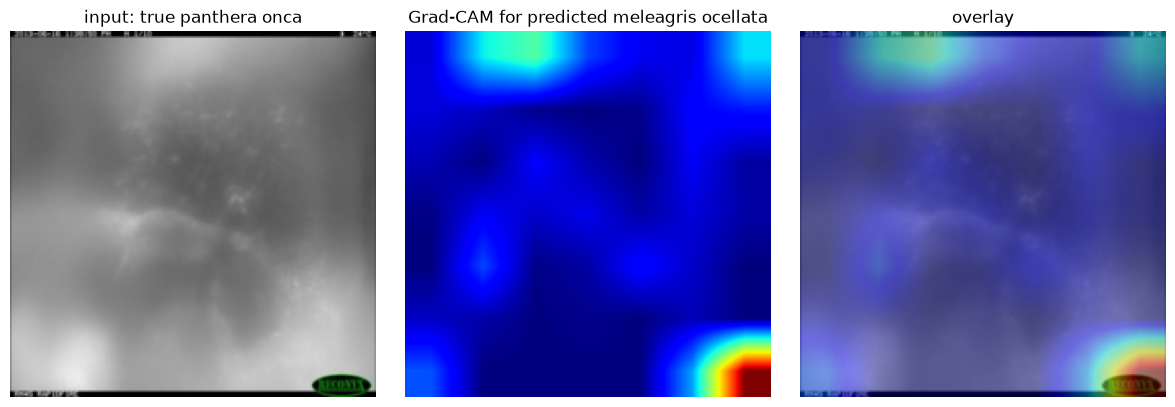

In [6]:
idx = int(np.argmax(y.cpu().numpy() == 5))       # a jaguar image if present, else whatever is there
img_t = x[idx:idx + 1]
feat_holder = {}
h = model.layer4.register_forward_hook(lambda m, i, o: feat_holder.update(activations=o))
scores = torch.nn.functional.softmax(model(img_t), 1)
h.remove()
acts = feat_holder["activations"].detach()
weights = model.fc.weight[scores.argmax(1).item()].detach()
cam = torch.relu((acts * weights.view(1, weights.shape[0], 1, 1)).sum(1))[0]
cam = torch.nn.functional.interpolate(cam[None][None].cpu(), size=(224, 224), mode="bilinear").squeeze()
cam = ((cam - cam.min()) / (cam.max() - cam.min() + 1e-8)).numpy()

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
mean_img = (img_t[0].cpu() * torch.tensor([0.229, 0.224, 0.225])[:, None, None]
            + torch.tensor([0.485, 0.456, 0.406])[:, None, None]).clamp(0, 1).numpy().transpose(1, 2, 0)
axes[0].imshow(mean_img); axes[0].set_title(f"input: true {class_map[int(y[idx])]}")
axes[1].imshow(cam, cmap="jet"); axes[1].set_title(f"Grad-CAM for predicted {class_map[int(scores.argmax(1).item())]}")
axes[2].imshow(mean_img); axes[2].imshow(cam, cmap="jet", alpha=0.45); axes[2].set_title("overlay")
for a in axes:
    a.axis("off")
plt.tight_layout(); plt.savefig(OUT / "gradcam.png", dpi=120)
print("layer4 activation shape:", tuple(acts.shape), "| predicted:", class_map[int(scores.argmax(1).item())],
      "| top prob:", round(float(scores.max()), 4), "| CAM pixels above 0.5:", int((cam > 0.5).sum()))

## 3. Gradient flow, counted

Backpropagation is the syllabus' core claim, so the evidence is the magnitude of the gradient at each
depth for one real loss - and a check that a frozen backbone really receives none.

In [7]:
model.train()
for p in model.parameters():
    p.requires_grad_(True)
logits = model(x)
loss = torch.nn.functional.cross_entropy(logits, y.to(DEVICE))
model.zero_grad()
loss.backward()
depths = ["conv1", "layer1", "layer2", "layer3", "layer4", "fc"]
grads = []
for name in depths:
    mod = getattr(model, name)
    gs = [p.grad for p in mod.parameters(recurse=True) if p.grad is not None]
    grads.append({"module": name, "grad_gnorm": round(float(torch.norm(torch.stack([g.flatten().norm() for g in gs]))), 5),
                  "max_abs": round(float(max(g.abs().max() for g in gs)), 6), "tensors": len(gs)})
print(pd.DataFrame(grads).to_string(index=False))

W.freeze_except(model, keep="fc")
model.zero_grad()
torch.nn.functional.cross_entropy(model(x), y.to(DEVICE)).backward()
frozen_g = [p.grad is not None and float(p.grad.abs().sum()) > 0
            for n, p in model.named_parameters() if not n.startswith("fc.")]
print("frozen backbone tensors reporting a non-zero gradient:", sum(frozen_g), "of", len(frozen_g))
assert sum(frozen_g) == 0, "freeze is not working"

module  grad_gnorm  max_abs  tensors
 conv1     2.36665 0.165311        1
layer1     2.41058 0.258994       30
layer2     2.11233 0.069985       39
layer3     2.31072 0.053717       57
layer4     1.79653 0.016849       30
    fc     2.18208 0.336801        2
frozen backbone tensors reporting a non-zero gradient: 0 of 159


## 4. 2D vs 3D convolution, measured

The syllabus lists 2D/3D convolution. A burst of camera-trap frames is a natural 3D input, so the cost of
that choice is measured here rather than hand-waved: same receptive field, same output channels, one stack
of frames instead of one image.

In [8]:
seq_rows = train_tbl.groupby("seq_id").filter(lambda g: len(g) >= 5).head(5)
frames = torch.stack([eval_tf(Image.open(IMG_ROOT / f).convert("RGB")) for f in seq_rows.filename])
stack = frames.transpose(0, 1).unsqueeze(0)                                    # [1, 5, 3, 224, 224]
conv2d = nn.Conv3d(3, 64, kernel_size=(5, 7, 7), stride=(1, 2, 2), padding=(2, 3, 3))
conv2d_eq = nn.Conv2d(3, 64, kernel_size=7, stride=2, padding=3)
out3, out2 = conv2d(stack), conv2d_eq(frames.reshape(-1, 3, 224, 224))
params3, params2 = sum(p.numel() for p in conv2d.parameters()), sum(p.numel() for p in conv2d_eq.parameters())
cmp = pd.DataFrame([
    {"model": "Conv3d (5-frame volume)", "out_shape": str(tuple(out3.shape)), "params": params3,
     "activation_MB_batch1": round(out3.numel() * out3.element_size() / 2**20, 2)},
    {"model": "Conv2d (same kernel per frame)", "out_shape": str(tuple(out2.shape)), "params": params2,
     "activation_MB_batch1": round(out2.numel() * out2.element_size() / 2**20, 2)},
])
cmp["params_x_vs_2d"] = (cmp.params / params2).round(2)
print(cmp.to_string(index=False))
print("\nA 3D stem multiplies the first layer's parameters by the temporal kernel (5x) and its activations "
      "by the number of frames, which is why this project keeps 2D CNNs for species and models time with a "
      "sequence model over visits instead.")

                         model            out_shape  params  activation_MB_batch1  params_x_vs_2d
       Conv3d (5-frame volume) (1, 64, 5, 112, 112)   47104                 15.31            4.97
Conv2d (same kernel per frame)    (5, 64, 112, 112)    9472                 15.31            1.00

A 3D stem multiplies the first layer's parameters by the temporal kernel (5x) and its activations by the number of frames, which is why this project keeps 2D CNNs for species and models time with a sequence model over visits instead.


## 5. Parameters versus hyperparameters, and the memory claim

The course distinguishes learned parameters from chosen hyperparameters, and the product claims edge
feasibility on a 6 GB laptop GPU. Both are recorded numerically.

In [9]:
torch.cuda.reset_peak_memory_stats() if DEVICE.type == "cuda" else None
t0 = time.time()
with torch.no_grad():
    _ = model(x)
fwd_ms = round((time.time() - t0) * 1000, 1)
peak_mb = round(torch.cuda.max_memory_allocated() / 2**20, 1) if DEVICE.type == "cuda" else None
ledger = pd.DataFrame([
    {"kind": "learned parameter", "item": "conv weights + bn scales/shifts + fc", "count": total_params,
     "set by": "gradient descent"},
    {"kind": "hyperparameter", "item": "learning rate / weight decay / batch / epochs / image size",
     "count": None, "set by": "the student, recorded in every experiment log"},
    {"kind": "hyperparameter", "item": "unfrozen modules", "count": sum(p.numel() for n, p in
     model.named_parameters() if p.requires_grad), "set by": "transfer-learning strategy"},
])
print(ledger.to_string(index=False))
print(f"\nbatch {x.shape[0]} forward pass: {fwd_ms} ms, peak GPU memory {peak_mb} MB on "
      f"{torch.cuda.get_device_name(0) if DEVICE.type=='cuda' else 'cpu'}")
print(f"model weights on disk: {sum(p.numel() for p in model.parameters()) * 4 / 2**20:.1f} MB fp32")

             kind                                                       item      count                                        set by
learned parameter                       conv weights + bn scales/shifts + fc 23534669.0                              gradient descent
   hyperparameter learning rate / weight decay / batch / epochs / image size        NaN the student, recorded in every experiment log
   hyperparameter                                           unfrozen modules    26637.0                    transfer-learning strategy

batch 13 forward pass: 13.2 ms, peak GPU memory 326.4 MB on NVIDIA GeForce RTX 3060 Laptop GPU
model weights on disk: 89.8 MB fp32


Read this notebook as the answer to three likely viva questions. "What are the tensor shapes?" — the
hook table, measured on real images. "How do you know it learns?" — Grad-CAM needs a gradient all the way
from the class score to `layer4`, and the gradient table shows magnitudes at each depth, plus a proof that
freezing really zeroes them. "Why not 3D convolution?" — the cost is quantified: 5x parameters and 5x
activations in the stem for a temporal kernel that a sequence model over visits gives more cheaply.